In [14]:
%pip install tensorflow-datasets
%pip install importlib-resources

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [15]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import confusion_matrix

import tensorflow as tf
import numpy as np
import seaborn as sns

from sklearn.metrics import confusion_matrix

from tensorflow.keras import Sequential, layers, models, callbacks
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Rescaling

from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

from tensorflow.keras import layers, models

In [16]:
import tensorflow_datasets as tfds
import tensorflow as tf

train_ds, test_ds = tfds.load(
    "tf_flowers",
    split=["train[:70%]", "train[70%:]"],
    as_supervised=True
)

print("Dataset carregado com sucesso!")

Dataset carregado com sucesso!


In [17]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

def preparar_imagem(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

train_ds = (
    train_ds
    .map(preparar_imagem, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(preparar_imagem, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Datasets preparados!")

Datasets preparados!


In [18]:
print("Estrutura do treino:")
print(train_ds.element_spec)

print("\nEstrutura do teste:")
print(test_ds.element_spec)

print("\nQuantidade de batches de treino:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Quantidade de batches de teste:",
      tf.data.experimental.cardinality(test_ds).numpy())

for imagens, labels in train_ds.take(1):
    print("\nShape das imagens:", imagens.shape)
    print("Shape dos labels:", labels.shape)
    print("Primeiros labels:", labels[:10].numpy())

Estrutura do treino:
(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))

Estrutura do teste:
(TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))

Quantidade de batches de treino: 81
Quantidade de batches de teste: 35

Shape das imagens: (32, 150, 150, 3)
Shape dos labels: (32,)
Primeiros labels: [0 4 2 0 0 1 2 3 3 1]


In [19]:
# Tamanho alvo já aplicado anteriormente
size = (150, 150)

# Converter labels para one-hot dentro do dataset
NUM_CLASSES = 5

def preparar_com_one_hot(image, label):
    label = tf.one_hot(label, depth=NUM_CLASSES)
    return image, label

train_ds = train_ds.map(
    preparar_com_one_hot,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preparar_com_one_hot,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Dados preparados!")

for imagens, labels in train_ds.take(1):
    print("Shape das imagens:", imagens.shape)
    print("Shape dos labels:", labels.shape)
    print("Primeiro label:", labels[0].numpy())

Dados preparados!
Shape das imagens: (32, 150, 150, 3)
Shape dos labels: (32, 5)
Primeiro label: [1. 0. 0. 0. 0.]


In [20]:
from tensorflow.keras import Sequential, layers
from tensorflow.keras.layers import Rescaling
from tensorflow.keras.callbacks import EarlyStopping

hand_model = Sequential([
    layers.Input(shape=(150, 150, 3)),
    Rescaling(1./255),

    layers.Conv2D(16, kernel_size=10, activation="relu"),
    layers.MaxPooling2D(3),

    layers.Conv2D(32, kernel_size=8, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(32, kernel_size=6, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Flatten(),
    layers.Dense(50, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(5, activation="softmax")
])

hand_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

es = EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    restore_best_weights=True
)

print("hand_model criado com sucesso!")

hand_model criado com sucesso!


In [21]:
history = hand_model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5,
    callbacks=[es]
)

Epoch 1/5


C:\Users\jotav\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.3025 - loss: 1.5078 - val_accuracy: 0.3188 - val_loss: 1.4623
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.4262 - loss: 1.3304 - val_accuracy: 0.4614 - val_loss: 1.3732
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.5021 - loss: 1.2052 - val_accuracy: 0.4941 - val_loss: 1.1671
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.5574 - loss: 1.1382 - val_accuracy: 0.5186 - val_loss: 1.1539
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - accuracy: 0.5574 - loss: 1.0985 - val_accuracy: 0.5395 - val_loss: 1.1507


In [22]:
loss, acc = hand_model.evaluate(test_ds)

print(f"A loss do modelo é {loss:.2f} e a ACC é {acc:.2f}")

35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5395 - loss: 1.1507
A loss do modelo é 1.15 e a ACC é 0.54


35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step


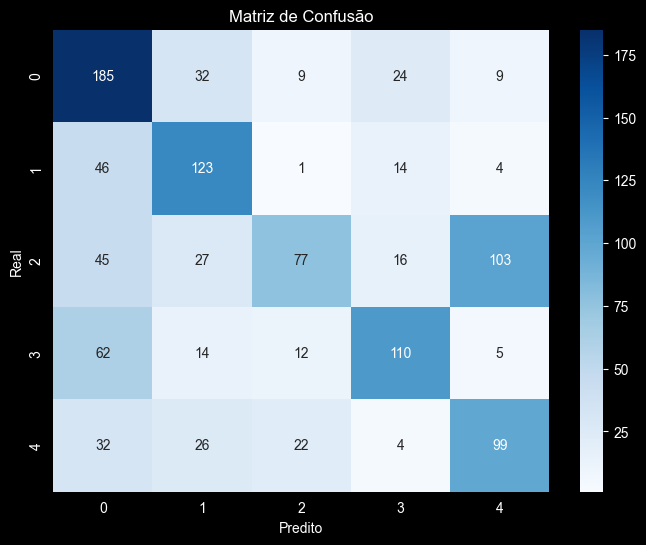

In [23]:
# Obter previsões do modelo
preds = hand_model.predict(test_ds)

# Extrair os labels verdadeiros do test_ds
test_labels = np.concatenate(
    [labels.numpy() for images, labels in test_ds],
    axis=0
)

# Como os labels estão em one-hot, converter para número da classe
labels_true = np.argmax(test_labels, axis=1)

# Converter previsões para número da classe
labels_pred = np.argmax(preds, axis=1)

# Criar matriz de confusão
cf_matrix = confusion_matrix(labels_true, labels_pred)

# Exibir matriz
plt.figure(figsize=(8, 6))
sns.heatmap(
    cf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()

In [24]:
# Pré-processamento específico da VGG16
def preprocessar_vgg(image, label):
    image = preprocess_input(image)
    return image, label

train_dsTL = train_ds.map(
    preprocessar_vgg,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dsTL = test_ds.map(
    preprocessar_vgg,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dsTL = train_dsTL.prefetch(tf.data.AUTOTUNE)
test_dsTL = test_dsTL.prefetch(tf.data.AUTOTUNE)

# Modelo base VGG16
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3)
)

# Congelar os pesos da VGG16
base_model.trainable = False

print("VGG16 carregada com sucesso!")

VGG16 carregada com sucesso!


In [25]:
# Observa a estrutura do modelo importado
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [26]:
# Define as camadas
flatten_layer = layers.Flatten()
dense_layer_1 = layers.Dense(50, activation="relu")
dense_layer_2 = layers.Dense(20, activation="relu")
prediction_layer = layers.Dense(5, activation="softmax")

# Estabelece o modelo completo
model = models.Sequential( [
    base_model,        # A base CNN vem da VGG16
    flatten_layer,     # Achata as features que saem da VGG16 (base_model)
    dense_layer_1,     # 1ª camada oculta fully connected
    dense_layer_2,     # 2ª camada oculta fully connected
    prediction_layer   # Camada de saída, com 5 neurônios para classificação
] )

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │       409,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 20)             │         1,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 5)              │           105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,125,463 (57.70 MB)

 Trainable params: 410,775 (1.57 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [28]:
# Compilar o modelo
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Early stopping
es = EarlyStopping(
    monitor="val_accuracy",
    patience=5,
    restore_best_weights=True
)

# Treinar
history = model.fit(
    train_dsTL,
    validation_data=test_dsTL,
    epochs=5,
    callbacks=[es]
)

Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.8895 - loss: 0.3756 - val_accuracy: 0.7738 - val_loss: 0.9538
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9159 - loss: 0.3771 - val_accuracy: 0.7611 - val_loss: 1.1732
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9412 - loss: 0.2644 - val_accuracy: 0.7947 - val_loss: 1.0697
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9595 - loss: 0.1590 - val_accuracy: 0.7893 - val_loss: 1.0468
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9770 - loss: 0.0935 - val_accuracy: 0.8056 - val_loss: 1.0402


In [29]:
# Avaliação do modelo: acurácia
loss, acc = model.evaluate(test_dsTL)

print(f"A loss do modelo é {loss:.2f} e a ACC é {acc:.2f}")




35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 716ms/step - accuracy: 0.8056 - loss: 1.0402
A loss do modelo é 1.04 e a ACC é 0.81


35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 700ms/step


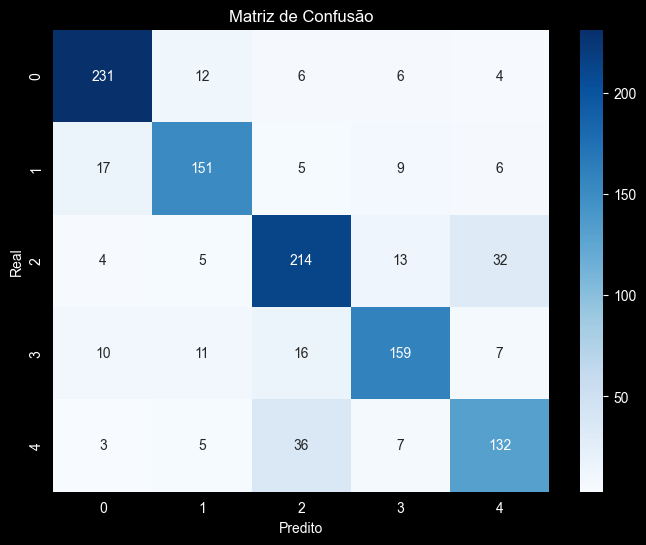

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Previsões
preds = model.predict(test_dsTL)

# Labels verdadeiros
test_labels = np.concatenate(
    [labels.numpy() for images, labels in test_dsTL],
    axis=0
)

# One-hot -> índice da classe
labels_true = np.argmax(test_labels, axis=1)
labels_pred = np.argmax(preds, axis=1)

# Matriz de confusão
cf_matrix = confusion_matrix(labels_true, labels_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cf_matrix, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()

In [ ]:
### TRANSFER LERANING + FINE TUNNING
